Importing dependancy

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from sklearn import datasets
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

Importing boston house price datasets

In [ ]:

url = "http://lib.stat.cmu.edu/datasets/boston"

raw = pd.read_csv(url, sep=r"\s+", skiprows=22, header=None)

data = np.hstack([raw.values[::2, :], raw.values[1::2, :2]])
target = raw.values[1::2, 2]

features_name = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX",
    "RM", "AGE", "DIS", "RAD", "TAX",
    "PTRATIO", "B", "LSTAT"
]

house_price_dataFrame = pd.DataFrame(data, columns=features_name)
house_price_dataFrame.head()


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33


In [ ]:
#add the target columns  to the DataFrame
house_price_dataFrame["price"] = target
house_price_dataFrame.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,price
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [ ]:
#checking number of row and columns in the dataFrame
house_price_dataFrame.shape

(506, 14)

In [ ]:
#check for missing values
house_price_dataFrame.isnull().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


In [ ]:
#statistitical process measure od dataset
house_price_dataFrame.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,price
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


Understanding correlation bet various features in the datset


In [ ]:
correlation =house_price_dataFrame.corr()

<Axes: >

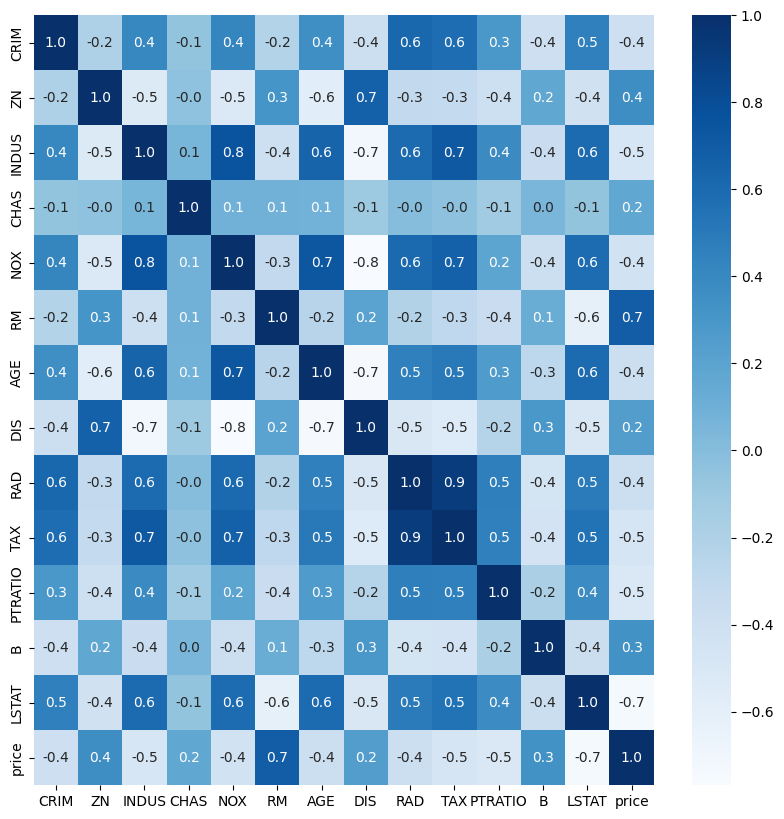

In [ ]:
#constructing heatMap to understand the correlation
plt.figure(figsize=(10,10))

sns.heatmap(
    correlation,
    cbar = True,
    fmt='.1f',
    annot=True,
    cmap="Blues"
)

Splitting the data and Target

In [ ]:
X = house_price_dataFrame.drop(columns=['price'],axis=1)
y=house_price_dataFrame["price"]

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

Model traning

```
1.XGB Regression

```



In [ ]:
#loading model
model = XGBRegressor()

In [ ]:
#traing a mmodel
model.fit(X_train , y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
#Evaluation
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
print("r2_score traing :",r2_score(y_train,y_pred_train))
print("r2_score testing :",r2_score(y_test,y_pred_test))

r2_score traing : 0.9999977822259297
r2_score testing : 0.8930821357033084


Visualization actual price and predicted price

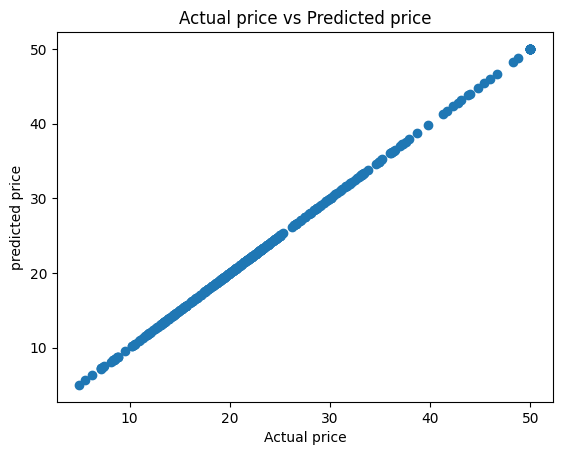

In [ ]:
plt.scatter(y_train,y_pred_train)
plt.xlabel("Actual price")
plt.ylabel("predicted price")
plt.title("Actual price vs Predicted price")
plt.show()

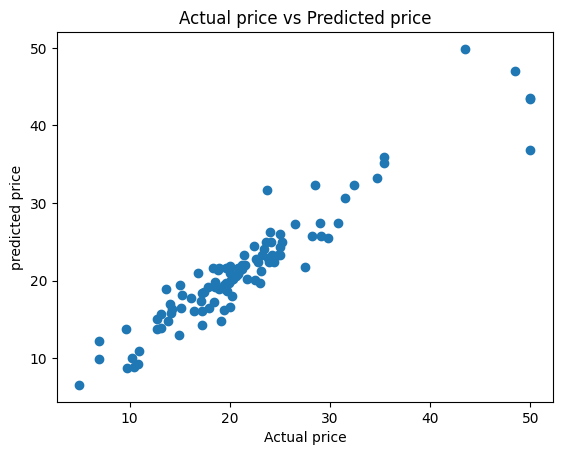

In [ ]:
plt.scatter(y_test,y_pred_test)
plt.xlabel("Actual price")
plt.ylabel("predicted price")
plt.title("Actual price vs Predicted price")
plt.show()